# Lab 4, Notebook A — Filtering the spectrum

*Linear Algebra for Data Science, UCU 2026. Uses Session 5.2 (SVD, Eckart–Young, truncated SVD, filter factors) and, for A3, the convolution theorem for the discrete Fourier transform.*

An image is a matrix, and the SVD sorts it into rank-one layers by importance. In this notebook you will keep, drop or shrink those layers for three different purposes: to **compress** an image (A1), to remove **noise** from it (A2), and to undo a **blur** (A3). The same idea runs through all three: write the problem in a basis where it is diagonal, then decide what to do with each coordinate. The last part also shows why a mathematically exact inverse can be numerically worthless.

**How to work.** Most tasks ask you to **predict first, in writing, then compute, then explain any difference**. Write the prediction *before* running the cell. A wrong prediction with an honest explanation earns more at the defence than a correct number you cannot explain.

**Rules.**
- Do not call `np.linalg.inv` or `np.linalg.pinv` anywhere.
- Never form the blur matrix of the full image (you will see in A3 why you cannot). The only explicit circulant matrix allowed is the small 1-D one in A3(a).
- You may use `np.linalg.svd`, `np.linalg.norm`, `scipy.linalg.qr` and `np.fft`. Library shortcuts such as `scipy.linalg.circulant` are allowed only where a cell says **check**.
- Do not change the seeds.
- Before you submit, run `Kernel → Restart & Run All`.

**Marking.** Core A is worth 2 points at the defence; the code point and the extension are shared with Notebook B.

**Contents.** A1 Compression and Eckart–Young · A2 Denoising · A3 Deblurring · Extension E1 (choosing λ without knowing the noise). Attempt **at most one** extension in the whole lab.

| | |
|---|---|
| **Team member 1** | *Vladyslav, Hryhola* |
| **Team member 2** | *Ihor, Kashuba* |
| **Extension attempted** (at most one in the whole lab) | *E1* |
| **Late days used on this lab** | *1* |
| **Runs top to bottom from a clean kernel** | *yes* |

python 3.14.6 | numpy 2.5.3 | scipy 1.18.1 | matplotlib 3.11.2 | sklearn 1.9.1
image: 427 x 640 = 273280 pixels


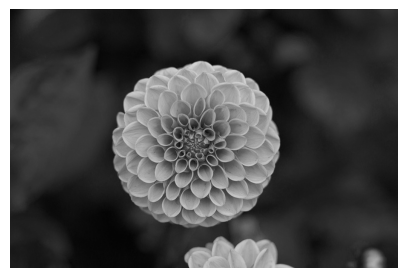

In [1]:
import sys, time
import numpy as np
import scipy, scipy.linalg as sl
import matplotlib, matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_sample_image

print("python", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| matplotlib", matplotlib.__version__, "| sklearn", sklearn.__version__)
np.set_printoptions(precision=4, suppress=False, linewidth=110)

img = load_sample_image("flower.jpg").astype(float).mean(axis=2) / 255   # grey levels in [0, 1]
m, n = img.shape
rel = lambda X: np.linalg.norm(X - img) / np.linalg.norm(img)            # relative Frobenius error
print(f"image: {m} x {n} = {m*n} pixels")
plt.figure(figsize=(5, 3.4)); plt.imshow(img, cmap="gray", vmin=0, vmax=1); plt.axis("off"); plt.show()

---
## A1. Compression and Eckart–Young

Write the SVD as $A = \sum_j \sigma_j \mathbf{u}_j\mathbf{v}_j^\top$. The truncated SVD $A_k = \sum_{j\le k}\sigma_j\mathbf{u}_j\mathbf{v}_j^\top$ is stored as $k$ columns of $U$, $k$ rows of $V^\top$ and $k$ singular values.

**(a)** Implement `rank_k(U, s, Vt, k)`, which returns $A_k$ from the thin SVD. Use broadcasting, not `np.diag`, and do not multiply by any zero columns.

In [2]:
U, s, Vt = np.linalg.svd(img, full_matrices=False)

def rank_k(U, s, Vt, k):
    # YOUR CODE HERE
    return (U[:, :k] * s[:k]) @ Vt[:k, :]

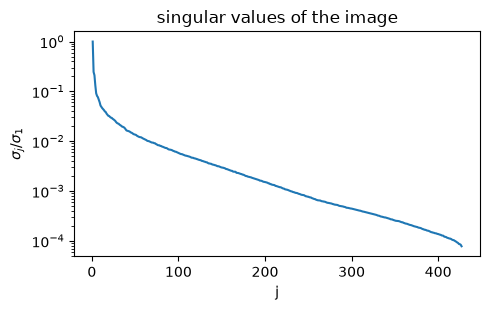

sigma_1 = 149.2, sigma_427 = 1.16e-02


In [3]:
# check
assert np.allclose(rank_k(U, s, Vt, len(s)), img)
assert np.linalg.matrix_rank(rank_k(U, s, Vt, 7)) == 7
plt.figure(figsize=(5, 3.2))
plt.semilogy(np.arange(1, len(s) + 1), s / s[0])
plt.xlabel("j"); plt.ylabel(r"$\sigma_j/\sigma_1$"); plt.title("singular values of the image"); plt.tight_layout(); plt.show()
print(f"sigma_1 = {s[0]:.1f}, sigma_{len(s)} = {s[-1]:.2e}")

**(b)** *Predict, then compute.* Implement two functions that use **only the singular values**:
- `predicted_errors(s, k)` returns the relative Frobenius error $\|A-A_k\|_F/\|A\|_F$ and the 2-norm error $\|A-A_k\|_2$ of the best rank-$k$ approximation;
- `storage(k, m, n)` returns the fraction of the $mn$ pixel values needed to store $A_k$ in factored form.

Before running the comparison below: will the actual errors of `rank_k` **equal** your predictions, or only be bounded by them? Name the theorem.

**Your prediction** *(write it before running the next cell)*:

I expect the actual errors to equal the predicted ones, since both are calculated from the same discarded singular values and outer product is dropped. Eckart–Young theorem guarantees that resulted approximated matrix is the best rank-k approximation.

In [4]:
def predicted_errors(s, k):
    # YOUR CODE HERE
    error_F = np.linalg.norm(s[k:]) # Frobenius norm of discarded singular values
    # The rank-one matrices u_i @ v_i.T are orthonormal under the Frobenius inner product.
    # Since each has Frobenius norm 1, Pythagoras lets us calculate
    # the reconstruction error using only the discarded singular values.

    A_F = np.linalg.norm(s) # Frobenius norm of full rank original matrix

    relative_F = error_F / A_F

    error_2 = s[k] if k < len(s) else 0.0 # largest discarded singular value
    # The spectral norm measures the maximum amount a matrix can stretch a unit vector,
    # so it would be the singular value for this case

    return relative_F, error_2

def storage(k, m, n):
    # YOUR CODE HERE
    return k * (m + n + 1) / (m * n)

In [5]:
# check
print("   k | predicted rel. F  actual rel. F | predicted 2-norm  actual 2-norm | storage")
for k in [5, 10, 20, 50, 100]:
    Ak = rank_k(U, s, Vt, k)
    pf, p2 = predicted_errors(s, k)
    af, a2 = rel(Ak), np.linalg.norm(img - Ak, 2)
    print(f"{k:4d} | {pf:16.4f} {af:14.4f} | {p2:16.3f} {a2:14.3f} | {storage(k, m, n):6.2%}")
    assert np.isclose(pf, af) and np.isclose(p2, a2)

   k | predicted rel. F  actual rel. F | predicted 2-norm  actual 2-norm | storage
   5 |           0.2209         0.2209 |           12.118         12.118 |  1.95%
  10 |           0.1704         0.1704 |            7.296          7.296 |  3.91%
  20 |           0.1255         0.1255 |            4.576          4.576 |  7.82%
  50 |           0.0674         0.0674 |            1.995          1.995 | 19.54%
 100 |           0.0323         0.0323 |            0.849          0.849 | 39.08%


**Your answer.** As predicted, actual error is equal to predicted.

**(c)** From the singular values alone, find the smallest $k$ with relative Frobenius error at most 10%, 5% and 2%, and the storage each needs. Then find the **break-even rank**, above which the factored form needs more storage than the image itself. Is this image "low-rank"? Compare with a JPEG file, which stores a typical photograph in roughly 5–10% of its raw size with no visible loss.

In [6]:
# YOUR CODE HERE
print("Target error | Smallest k | Actual error | Storage")

for target in [0.10, 0.05, 0.02]:
    for k in range(len(s) + 1):
        error, _ = predicted_errors(s, k)

        if error <= target:
            print(
                f"{target:12.0%} | {k:10d} | "
                f"{error:12.2%} | {storage(k, m, n):7.2%}"
            )
            break

break_even = m * n / (m + n + 1)
largest_k = m * n // (m + n + 1)

print(f"\nBreak-even point: {break_even:.2f}")
print(f"Largest rank using no more storage than the image: {largest_k}")
print(f"More storage than the image from rank {largest_k + 1}")
print("Original rank:", np.linalg.matrix_rank(img))
print("Number of singular values:", len(s))

Target error | Smallest k | Actual error | Storage
         10% |         30 |        9.82% |  11.72%
          5% |         70 |        4.95% |  27.36%
          2% |        136 |        2.00% |  53.15%

Break-even point: 255.88
Largest rank using no more storage than the image: 255
More storage than the image from rank 256
Original rank: 427
Number of singular values: 427


**Your answer.** The break-even value is approximately 255.88, so the factored form uses more storage than the original image from rank 256 onward. The image can be compressed using SVD, but getting only 2% error still requires 53% of the original storage. JPEG is much more efficient at around 5–10%, although the image quality isn't directly comparable.

**(d)** *A competitor.* Instead of singular vectors, use $k$ **actual columns** of the image: choose them by QR with column pivoting, $AP = QR$, and project the whole image onto the span of the first $k$ columns of $Q$. Implement `column_subset_approx(A, k)`, returning the approximation and the indices of the chosen columns.

*Predict before running:* at $k = 20$, will its error be smaller, equal or larger than that of $A_{20}$? Is there any $k$ at which it could win?

**Your prediction**: I think SVD would be better that QR since according to Eckart–Young theorem the best rank-k approximation is SVD, so the error should be bigger for QR with same rank.

In [7]:
def column_subset_approx(A, k):
    # YOUR CODE HERE
    Q, R, piv = sl.qr(A, mode="economic", pivoting=True)

    Qk = Q[:, :k]
    approximation = Qk @ (Qk.T @ A)
    columns = piv[:k]

    return approximation, columns

k = 20
Ac, cols = column_subset_approx(img, k)
print(f"k = {k}: column subset error {rel(Ac):.4f}, truncated SVD error {rel(rank_k(U, s, Vt, k)):.4f}")
print("chosen columns:", np.sort(cols))

k = 20: column subset error 0.2030, truncated SVD error 0.1255
chosen columns: [194 215 240 273 280 284 290 296 301 308 318 326 331 340 360 383 409 430 434 443]


**Your answer.** As predicted, SVD wins. The column-subset approximation cannot have smaller error than truncated SVD at the same rank, although it can tie.

**(e)** Look at the approximations below. Where in the image is the error at $k = 30$ concentrated? Explain why, using the fact that each layer $\sigma_j\mathbf{u}_j\mathbf{v}_j^\top$ is an outer product.

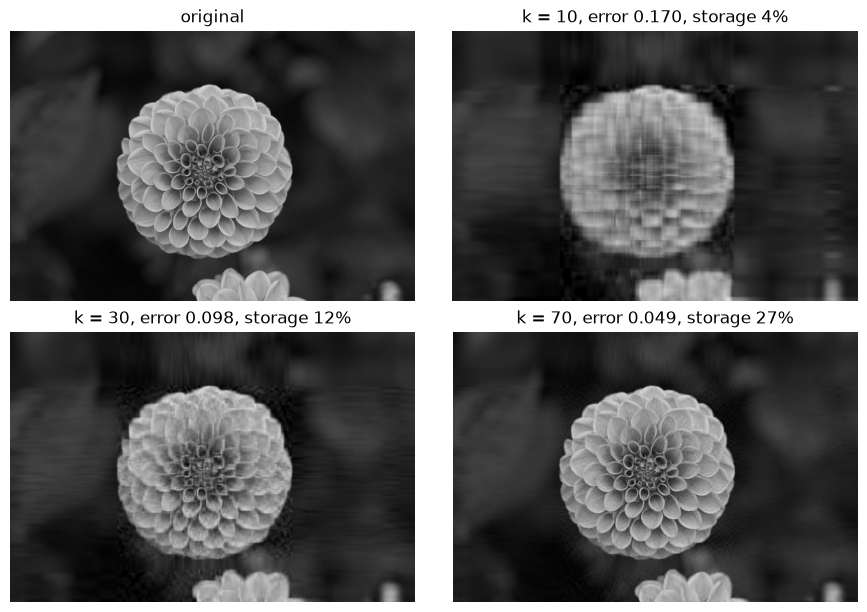

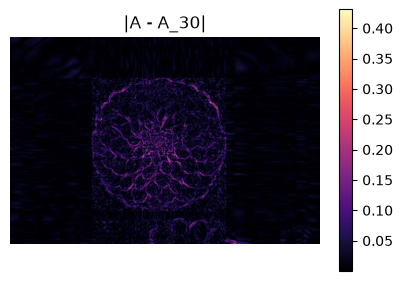

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(9, 6.2))
for a, k in zip(ax.flat, [None, 10, 30, 70]):
    X = img if k is None else rank_k(U, s, Vt, k)
    a.imshow(np.clip(X, 0, 1), cmap="gray", vmin=0, vmax=1); a.axis("off")
    a.set_title("original" if k is None else f"k = {k}, error {rel(X):.3f}, storage {storage(k, m, n):.0%}")
plt.tight_layout(); plt.show()
plt.figure(figsize=(5, 3.4)); plt.imshow(np.abs(img - rank_k(U, s, Vt, 30)), cmap="magma"); plt.axis("off")
plt.title("|A - A_30|"); plt.colorbar(); plt.show()

**Your answer.** The largest errors are concentrated around the flower's petals and edges, where the image has many fine details. The first SVD layers capture the main patterns, while later layers often capture finer details. Since we discard those later layers, some of the fine details are lost.

Each outer product combines one vertical pattern with one horizontal pattern; the curved petal edges need many such patterns, so a small number of layers cannot reproduce them accurately.

---
## A2. Denoising

Now we observe $Y = A + E$, where the entries of $E$ are independent $\mathcal N(0, \text{sd}^2)$. Two facts, stated without proof:

- **Weyl's inequality** for singular values: $|\sigma_j(A+E) - \sigma_j(A)| \le \|E\|_2$ for every $j$.
- **Noise floor.** For an $m\times n$ matrix with independent $\mathcal N(0,\text{sd}^2)$ entries and $m, n$ large, $\|E\|_2 \approx \text{sd}\,(\sqrt m + \sqrt n)$.

So singular values of $A$ well below the floor are drowned by the noise, and those well above it survive with a small shift. This suggests keeping only the singular values of $Y$ that stand above the floor.

In [9]:
sd = 0.05
E = sd * np.random.default_rng(4).standard_normal((m, n))
Y = img + E
print(f"sd = {sd}: error of the noisy image {rel(Y):.4f}")

sd = 0.05: error of the noisy image 0.1606


**(a)** *Predict, then compute.* Predict $\|E\|_2$ from the noise-floor formula. Then compute it, and check Weyl's inequality: compute $\max_j|\sigma_j(Y) - \sigma_j(A)|$ and compare it with $\|E\|_2$.

**Your prediction**: I expect the spectral norm of the noise to be around 2.3, according to the noise-floor formula:
$\|E\|_2 \approx 0.05(\sqrt{427}+\sqrt{640}) \approx 2.3$
The maximum change in singular values should be no greater than the actual noise norm, according to Weyl's inequality.

In [10]:
# YOUR CODE HERE
# Predict the noise spectral norm
predicted_norm = sd * (np.sqrt(m) + np.sqrt(n))

# Compute the actual noise spectral norm
actual_norm = np.linalg.norm(E, 2)

# Calculate the singular values of the noisy image
sY = np.linalg.svd(Y, compute_uv=False)

# Find the largest change in singular values
max_change = np.max(np.abs(sY - s))

print(f"Predicted noise norm: {predicted_norm:.4f}")
print(f"Actual noise norm:    {actual_norm:.4f}")
print(f"Maximum SV change:    {max_change:.4f}")

# Check Weyl's inequality (allowing numerical rounding)
assert max_change <= actual_norm + 1e-10

Predicted noise norm: 2.2981
Actual noise norm:    2.3033
Maximum SV change:    1.1512


**Your answer.** The predicted noise norm is very close to the actual value. The maximum singular-value change is below the noise norm, so Weyl's inequality holds.

**(b)** Plot the singular values of $A$ and of $Y$ together with the floor. Then compare two choices of the rank for the truncated SVD of $Y$:
- the **threshold rule** $k_{\text{thr}} = \#\{j : \sigma_j(Y) > \text{floor}\}$;
- the **oracle** $k_{\text{or}}$, the rank that minimises the error against the clean image, found by trying $k = 1,\dots,200$.

Report both ranks and errors. Why can the oracle not be used in practice?

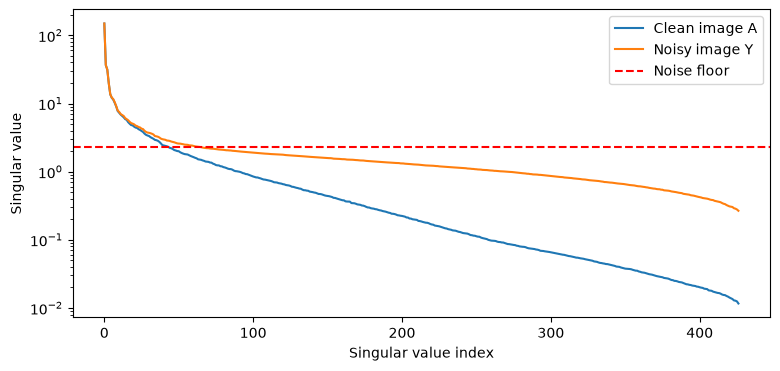

In [11]:
# YOUR CODE HERE
UY, sY, VYt = np.linalg.svd(Y, full_matrices=False)

floor = sd * (np.sqrt(m) + np.sqrt(n))

plt.figure(figsize=(9, 4))

plt.semilogy(s, label="Clean image A")
plt.semilogy(sY, label="Noisy image Y")
plt.axhline(floor, color="red", linestyle="--", label="Noise floor")

plt.xlabel("Singular value index")
plt.ylabel("Singular value")
plt.legend()
plt.show()

In [12]:
# 1. Threshold rank
k_thr = np.count_nonzero(sY > floor)

Y_thr = rank_k(UY, sY, VYt, k_thr)
error_thr = rel(Y_thr)

# 2. Oracle rank: try k = 1, ..., 200
errors = []

for k in range(1, 201):
    Yk = rank_k(UY, sY, VYt, k)
    errors.append(rel(Yk))

k_or = np.argmin(errors) + 1
error_or = errors[k_or - 1]

print(f"Threshold: k = {k_thr}, error = {error_thr:.4f}")
print(f"Oracle:    k = {k_or}, error = {error_or:.4f}")

Threshold: k = 65, error = 0.1031
Oracle:    k = 52, error = 0.1009


**Your answer.** The threshold rule gives k = 65 with 10.31% error, while the oracle gives k = 52 with 10.09% error. The oracle performs slightly better because it chooses the rank that minimizes the actual error.

However, we cannot use the oracle in practice because we don't know the original clean image needed to calculate that error.

**(c)** Truncation keeps a layer completely or drops it completely. A softer choice multiplies layer $j$ by a **filter factor**
$$f_j = \frac{\sigma_j^2}{\sigma_j^2 + \lambda},$$
the same factors as in Tikhonov regularisation (frame `tikhonov-filter`). Implement `filter_factors(s, lam)` and `spectral_filter(U, s, Vt, f)`, which returns $\sum_j f_j\sigma_j\mathbf{u}_j\mathbf{v}_j^\top$. Use $\lambda = \text{floor}^2$: what is $f_j$ for a singular value exactly at the floor? Compare the error with (b).

In [13]:
def filter_factors(s, lam):
    # YOUR CODE HERE
    return s**2 / (s**2 + lam)

def spectral_filter(U, s, Vt, f):
    # YOUR CODE HERE
    return (U * (f * s)) @ Vt

In [14]:
# check
assert np.allclose(spectral_filter(U, s, Vt, np.ones_like(s)), img)
f = filter_factors(sY, floor ** 2)
print(f"soft filter, lambda = floor^2: error {rel(spectral_filter(UY, sY, VYt, f)):.4f}; "
      f"effective rank sum(f) = {f.sum():.1f}")

soft filter, lambda = floor^2: error 0.0933; effective rank sum(f) = 121.7


**Your answer.** At the noise floor, the filter factor is 0.5. Soft filtering gives 9.33% error, which is better than both the threshold rule (10.31%) and the oracle (10.09%). This is possible because the oracle only finds the best rank for hard truncation, while soft filtering reduces the strength of individual layers instead of completely removing them. The effective rank is 121.7.

**(d)** *Predict, then compute.* Double the noise, $\text{sd} = 0.1$ (same seed). Will the oracle rank go up or down, and roughly by how much? Then repeat (a)–(c) for $\text{sd} = 0.1$. Write a function `denoise_report(sd)` that prints the floor, $\|E\|_2$, the noisy error, both ranks with their errors, and the soft-filter error; run it for both noise levels.

**Your prediction**: I expect the oracle rank to decrease almost twice, because stronger noise makes more of the weaker SVD layers less useful.


sd = 0.05
Noise floor:       2.2981
Actual noise norm: 2.3033
Max SV change:     1.1512
Noisy error:       0.1606
Threshold: k = 65, error = 0.1031
Oracle:    k = 52, error = 0.1009
Soft filter error: 0.0933
Effective rank:    121.7


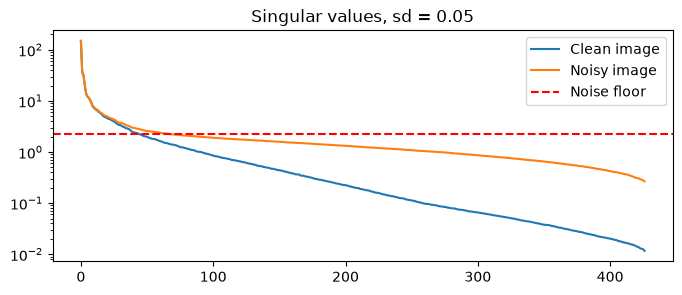


sd = 0.1
Noise floor:       4.5962
Actual noise norm: 4.6066
Max SV change:     2.6580
Noisy error:       0.3212
Threshold: k = 35, error = 0.1608
Oracle:    k = 27, error = 0.1549
Soft filter error: 0.1568
Effective rank:    105.8


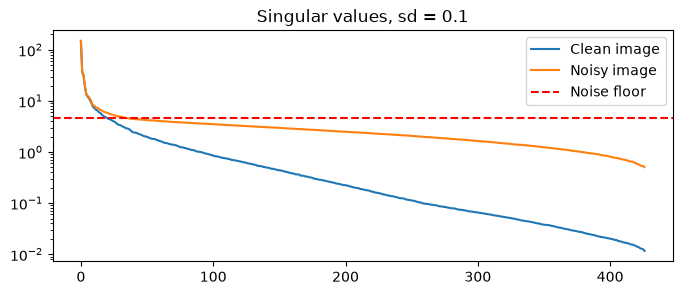

In [15]:
def denoise_report(sd):
    # YOUR CODE HERE
    # Generate noise using the same seed
    E = sd * np.random.default_rng(4).standard_normal((m, n))
    Y = img + E

    # SVD of noisy image
    UY, sY, VYt = np.linalg.svd(Y, full_matrices=False)

    # A2(a): noise floor and Weyl's inequality
    floor = sd * (np.sqrt(m) + np.sqrt(n))
    actual_norm = np.linalg.norm(E, 2)
    max_change = np.max(np.abs(sY - s))

    # A2(b): threshold rank
    k_thr = np.count_nonzero(sY > floor)
    error_thr = rel(rank_k(UY, sY, VYt, k_thr))

    # A2(b): oracle rank
    errors = []
    Yk = np.zeros_like(img)

    for j in range(200):
        Yk += sY[j] * np.outer(UY[:, j], VYt[j, :])
        errors.append(rel(Yk))

    k_or = np.argmin(errors) + 1
    error_or = errors[k_or - 1]

    # A2(c): soft filtering
    f = filter_factors(sY, floor**2)
    error_soft = rel(spectral_filter(UY, sY, VYt, f))

    # Report
    print(f"\nsd = {sd}")
    print(f"Noise floor:       {floor:.4f}")
    print(f"Actual noise norm: {actual_norm:.4f}")
    print(f"Max SV change:     {max_change:.4f}")
    print(f"Noisy error:       {rel(Y):.4f}")
    print(f"Threshold: k = {k_thr}, error = {error_thr:.4f}")
    print(f"Oracle:    k = {k_or}, error = {error_or:.4f}")
    print(f"Soft filter error: {error_soft:.4f}")
    print(f"Effective rank:    {f.sum():.1f}")

    # Plot the singular values
    plt.figure(figsize=(8, 3))
    plt.semilogy(s, label="Clean image")
    plt.semilogy(sY, label="Noisy image")
    plt.axhline(floor, color="red", linestyle="--", label="Noise floor")
    plt.title(f"Singular values, sd = {sd}")
    plt.legend()
    plt.show()

for sd_ in [0.05, 0.1]:
    denoise_report(sd_)

**Your answer.** Doubling the noise reduced the oracle rank from 52 to 27, which is close to my prediction. The noise floor and noisy image error doubled, while the denoising errors increased. This makes sense because stronger noise means we need to discard more SVD layers, losing more image details.

Soft filtering performed better at sd = 0.05, but at sd = 0.1 the oracle had a slightly lower error.

**(e)** At $\text{sd} = 0.05$ the best truncation reduces the error from about 16% to about 10%. Why is the gain so modest? Give two reasons, one about the spectrum you plotted in A1(a) and one about the noise that remains in the kept layers. (*Hint:* how many numbers does a rank-$k$ matrix have, and how much noise lands in each?)

**Your answer.** The improvement is limited for two reasons. First, the singular values decrease gradually, so removing more layers also removes useful image details. Second, noise is present in the retained layers too, so truncation cannot remove all of it.

---
## A3. Deblurring

A camera that is slightly out of focus replaces each pixel by a weighted average of its neighbours. With **periodic** boundary conditions (the image wraps around at the edges) this is a 2-D **circular convolution** with a kernel $c$, here a Gaussian of width $w = 2$ pixels:
$$b = c \circledast x + e, \qquad e \sim \mathcal N(0, \eta^2 I).$$
As a matrix acting on the vectorised image, the blur $C$ is $mn \times mn$ and **block circulant with circulant blocks**. The convolution theorem says $\operatorname{fft2}(c \circledast x) = \operatorname{fft2}(c)\cdot\operatorname{fft2}(x)$ entrywise, so $C = F^{-1}\operatorname{diag}(\hat c)F$, where $F$ is the 2-D DFT and $\hat c = \operatorname{fft2}(c)$. Since $F/\sqrt{mn}$ is unitary, the singular values of $C$ are the numbers $|\hat c_j|$ and the singular vectors are Fourier modes. **The SVD of the blur costs one FFT.**

In [16]:
def kernel(m, n, w):
    # periodic Gaussian blur kernel centred at pixel (0, 0), entries sum to 1
    i = np.minimum(np.arange(m), m - np.arange(m))
    j = np.minimum(np.arange(n), n - np.arange(n))
    K = np.exp(-(i[:, None] ** 2 + j[None, :] ** 2) / (2 * w ** 2))
    return K / K.sum()

w = 2.0
kh = np.fft.fft2(kernel(m, n, w))                                 # the "singular values", with phases
blur = lambda X: np.real(np.fft.ifft2(np.fft.fft2(X) * kh))       # X -> C X, never forming C

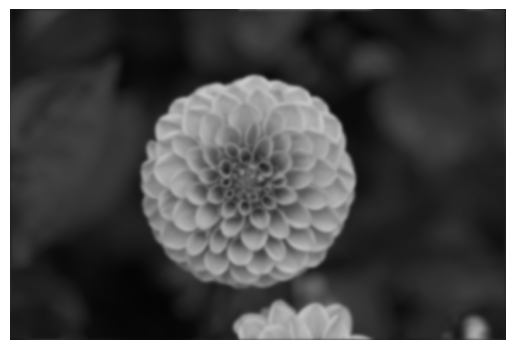

In [17]:
blurred_img = blur(img)

plt.imshow(blurred_img, cmap="gray", vmin=0, vmax=1)
plt.axis("off")
plt.show()

**(a)** *The 1-D version, explicitly.* For a vector $c\in\mathbb R^N$ the circulant matrix has entries $C_{ij} = c_{(i-j) \bmod N}$, so that $C\mathbf x = c\circledast\mathbf x$. Implement `circulant(c)`, **check** it against `scipy.linalg.circulant`, and check that $C\mathbf x$ equals the FFT formula. Then confirm that the singular values of $C$ for the 64-point kernel below are the numbers $|\hat c_j|$, up to order.

In [18]:
def circulant(c):
    # YOUR CODE HERE
    N = len(c)

    i = np.arange(N)[:, None]
    j = np.arange(N)[None, :]

    return c[(i - j) % N]

In [19]:
# test
c = np.array([0.6, 0.2, 0, 0.2])
print(circulant(c))

[[0.6 0.2 0.  0.2]
 [0.2 0.6 0.2 0. ]
 [0.  0.2 0.6 0.2]
 [0.2 0.  0.2 0.6]]


In [20]:
# check
c1 = kernel(64, 1, w)[:, 0]
C1 = circulant(c1)
x1 = np.random.default_rng(0).standard_normal(64)
assert np.allclose(C1, sl.circulant(c1))
assert np.allclose(C1 @ x1, np.real(np.fft.ifft(np.fft.fft(c1) * np.fft.fft(x1))))
sv = np.sort(np.linalg.svd(C1, compute_uv=False))
print("singular values of C equal |fft(c)|:", np.allclose(sv, np.sort(np.abs(np.fft.fft(c1)))))
print("largest and smallest:", sv[-1], sv[0])

singular values of C equal |fft(c)|: True
largest and smallest: 1.0 5.3505759609979725e-09


**(b)** *Cost.* Compute the memory, in GB, needed to store $C$ for our image as a dense `float64` matrix, and the order of magnitude of the flop count of its SVD ($\approx (mn)^3$ up to a modest constant). Compare with the cost of one 2-D FFT, about $5\,mn\log_2(mn)$ flops. What is the largest image whose $C$ fits into 16 GB of memory?

In [21]:
N = m * n

# Dense matrix memory in GB
memory_gb = N**2 * 8 / 1e9

# Approximate computational costs
svd_flops = N**3
fft_flops = 5 * N * np.log2(N)

# Maximum number of pixels for 16 GB
max_pixels = int(np.sqrt(16e9 / 8))
square_side = int(np.sqrt(max_pixels))

print(f"Dense C memory: {memory_gb:.2f} GB")
print(f"SVD flops: {svd_flops:.3e}")
print(f"FFT flops: {fft_flops:.3e}")
print(f"Maximum pixels: {max_pixels}")
print(f"Largest square image: {square_side} x {square_side}")

Dense C memory: 597.46 GB
SVD flops: 2.041e+16
FFT flops: 2.468e+07
Maximum pixels: 44721
Largest square image: 211 x 211


**Your answer.** The dense blur matrix would require about 597 GB of memory. Its SVD would take roughly $2.04\times10^{16}$ operations, compared with only $2.47\times10^7$ for an FFT.

With 16 GB of memory, the largest square image would be about 211 × 211 pixels. This shows why using FFT is much more practical than storing the full blur matrix.

**(c)** *Predict, then compute.* The blurred image is observed with noise of size $\eta = 10^{-3}$ per pixel, a quarter of one grey level in an 8-bit image. Compute the condition number $\kappa(C) = \max|\hat c_j| / \min|\hat c_j|$. Then predict:
1. the size of the error of the **naive inverse** $x = C^{-1}b$ (divide by $\hat c$ in Fourier space);
2. the error of the naive inverse applied to the blurred image **without** noise.

Then compute both, together with the error of the blurred image itself.

In [22]:
condC = np.max(np.abs(kh)) / np.min(np.abs(kh))

print("Condition number: k(C)", condC)

Condition number: k(C) 8.384936573489969e+18


**Your prediction**:
1. Since the condition number is extremely large, I would expect the noise to be amplified dramatically. The reconstructed image may be much worse than the blurred image
2. Mathematically, in exact arithmetic, we should recover the original image if the blur operator is invertible: $C^{-1}(Cx)=x$ However, computers use finite-precision numbers. Even B0 contains tiny rounding errors from FFT calculations. Since some Fourier coefficients are extremely close to zero, dividing by them can amplify those rounding errors too.

In [23]:
eta = 1e-3
noise = np.random.default_rng(11).standard_normal((m, n))     # one fixed draw, scaled by eta below
B0 = blur(img)                                                  # noise-free blurred image
B = B0 + eta * noise
print(f"eta = {eta}: error of the blurred image {rel(B):.4f}")

eta = 0.001: error of the blurred image 0.1086


In [24]:
def deblur_naive(B, kh):
    # YOUR CODE HERE
    return np.real(
        np.fft.ifft2(np.fft.fft2(B) / kh)
    )

# YOUR CODE HERE: condition number, and the errors of deblur_naive on B and on B0

# Recover from noisy and noise-free blurred images
recovered = deblur_naive(B, kh)
recovered_clean = deblur_naive(B0, kh)

print(f"Condition number:       {condC:.3e}")
print(f"Blurred image error:    {rel(B):.4f}")
print(f"Noisy inverse error:    {rel(recovered):.4f}")
print(f"Noise-free inverse:     {rel(recovered_clean):.4f}")

Condition number:       8.385e+18
Blurred image error:    0.1086
Noisy inverse error:    37260711024073.0000
Noise-free inverse:     8.5445


**Your answer.** The condition number is extremely large (about $8.38 \times 10^{18}$). The blurred image has an error of 0.1086, but naive inversion increases it to about 37 trillion with noise, and 8.54 even without noise.

This happens because dividing by very small Fourier coefficients greatly amplifies both noise and floating-point rounding errors. So naive inversion is not reliable, and regularization is needed.

**(d)** Implement two regularised inverses, both in Fourier space:
- `deblur_tikhonov(B, kh, lam)` with filter factors $f_j = |\hat c_j|^2/(|\hat c_j|^2+\lambda)$, that is $\hat x = \overline{\hat c}\,\hat b/(|\hat c|^2+\lambda)$;
- `deblur_tsvd(B, kh, tau)`, the truncated SVD: keep $\hat b_j/\hat c_j$ where $|\hat c_j| > \tau$ and set the rest to zero.

Sweep $\lambda$ and $\tau$ over the grids below and plot both errors on one axis against $\lambda$ and $\tau^2$. Report the best value of each (the oracle) and the fraction of frequencies the best truncation keeps. Explain from the filter factors why the best $\tau$ is close to $\sqrt\lambda$.

Tikhonov: lambda = 5.623e-04, error = 0.0667
TSVD: tau = 1.778e-02, error = 0.0697
TSVD frequencies kept: 16.04%


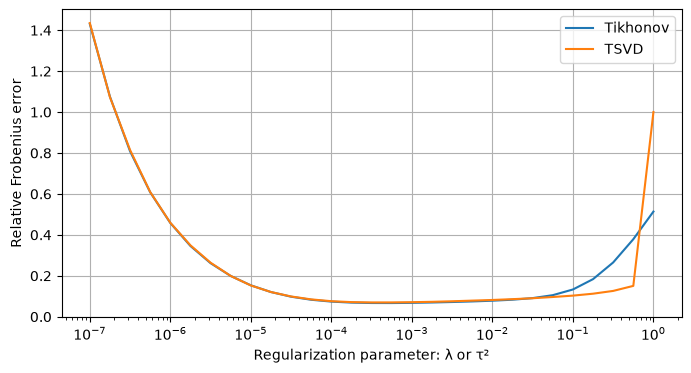

In [25]:
def deblur_tikhonov(B, kh, lam):
    # YOUR CODE HERE
    Bhat = np.fft.fft2(B)

    Xhat = np.conj(kh) * Bhat / (np.abs(kh)**2 + lam)

    return np.fft.ifft2(Xhat).real

def deblur_tsvd(B, kh, tau):
    # YOUR CODE HERE
    Bhat = np.fft.fft2(B)

    keep = np.abs(kh) > tau

    Xhat = np.zeros_like(Bhat)
    Xhat[keep] = Bhat[keep] / kh[keep]

    return np.fft.ifft2(Xhat).real

lams = 10.0 ** np.arange(-7, 0.01, 0.25)
taus = np.sqrt(lams)
# YOUR CODE HERE: errors over the grids, the two oracles, and the plot

# Calculate reconstruction errors for every parameter
tik_errors = [
    rel(deblur_tikhonov(B, kh, lam))
    for lam in lams
]

tsvd_errors = [
    rel(deblur_tsvd(B, kh, tau))
    for tau in taus
]

# Find the smallest error in each list
i_tik = np.argmin(tik_errors)
i_tsvd = np.argmin(tsvd_errors)

best_lam = lams[i_tik]
best_tau = taus[i_tsvd]

# Fraction of frequencies retained by the best TSVD
fraction_kept = np.mean(np.abs(kh) > best_tau)

print(f"Tikhonov: lambda = {best_lam:.3e}, error = {tik_errors[i_tik]:.4f}")
print(f"TSVD: tau = {best_tau:.3e}, error = {tsvd_errors[i_tsvd]:.4f}")
print(f"TSVD frequencies kept: {fraction_kept:.2%}")

plt.figure(figsize=(8, 4))

plt.semilogx(lams, tik_errors, label="Tikhonov")
plt.semilogx(taus**2, tsvd_errors, label="TSVD")

plt.xlabel("Regularization parameter: λ or τ²")
plt.ylabel("Relative Frobenius error")
plt.legend()
plt.grid(True)
plt.show()

**Your answer.** Tikhonov gives $6.67\%$ error with $\lambda = 0.0005623$, while TSVD gives $6.97\%$ with $\tau = 0.01778$, keeping only $16.04\%$ of the frequencies.

Tikhonov performs slightly better. The best $\tau$ is close to $\sqrt{\lambda} \approx 0.0237$ because both methods filter frequencies around the same threshold, but Tikhonov reduces them gradually while TSVD discards them completely.

**(e)** *Choosing $\lambda$ without the truth.* The true image leaves the residual $\|Cx - b\| = \|e\| \approx \eta\sqrt{mn}$. The **discrepancy principle** asks the same of the reconstruction: choose the largest $\lambda$ on the grid with $\|Cx_\lambda - b\| \le \eta\sqrt{mn}$. Explain why it would be a bad idea to ask for a much smaller residual.

Implement `discrepancy_lambda(B, kh, eta, lams)`. Compute the residual in Fourier space: by Parseval, $\|r\| = \|\hat r\|/\sqrt{mn}$ with $\hat r = (1 - f)\,\hat b$. Then, for $\eta = 10^{-3}$ and $\eta = 10^{-2}$ (same `noise` draw), report the oracle $\lambda$ and the discrepancy $\lambda$ with their errors. How much do you lose by not knowing the true image?

In [26]:
def discrepancy_lambda(B, kh, eta, lams):
    # YOUR CODE HERE
    Bhat = np.fft.fft2(B)
    power = np.abs(kh)**2

    # Expected noise norm
    target = eta * np.sqrt(B.size)

    valid_lams = []

    for lam in lams:
        # Tikhonov filter factors
        f = power / (power + lam)

        # Residual in Fourier space
        rhat = (1 - f) * Bhat

        # Parseval's theorem
        residual = np.linalg.norm(rhat) / np.sqrt(B.size)

        if residual <= target:
            valid_lams.append(lam)

    # Largest lambda satisfying the discrepancy principle
    return max(valid_lams) if valid_lams else None

# YOUR CODE HERE: the comparison table for eta = 1e-3 and 1e-2
print(
    f"{'eta':>8} | {'oracle λ':>12} | {'oracle error':>12} | "
    f"{'discrepancy λ':>14} | {'disc. error':>11} | {'extra error':>11}"
)

for eta_ in [1e-3, 1e-2]:
    B_eta = B0 + eta_ * noise

    errors = [rel(deblur_tikhonov(B_eta, kh, lam)) for lam in lams]

    best_idx = np.argmin(errors)
    oracle_lam = lams[best_idx]
    oracle_error = errors[best_idx]

    disc_lam = discrepancy_lambda(B_eta, kh, eta_, lams)
    disc_error = rel(deblur_tikhonov(B_eta, kh, disc_lam))

    extra_error = 100 * (disc_error - oracle_error)

    print(
        f"{eta_:8.0e} | {oracle_lam:12.3e} | {oracle_error:12.4f} | "
        f"{disc_lam:14.3e} | {disc_error:11.4f} | {extra_error:10.2f} pp"
    )

     eta |     oracle λ | oracle error |  discrepancy λ | disc. error | extra error
   1e-03 |    5.623e-04 |       0.0667 |      5.623e-04 |      0.0667 |       0.00 pp
   1e-02 |    1.778e-02 |       0.0894 |      1.000e-02 |      0.0900 |       0.05 pp


**Your answer.** The discrepancy principle gives the same result as the oracle for $\eta = 0.001$. With $\eta = 0.01$, the error is only 0.05 percentage points higher.

This shows that we can choose a good regularization parameter without knowing the original image. Asking for a much smaller residual would be a bad idea because we would start fitting the noise instead of removing it.

**(f)** Show a crop of the true image, the blurred noisy image, the naive inverse, and the discrepancy-principle reconstruction, for $\eta = 10^{-3}$. Which details come back, and which do not? Relate what you see to the frequencies that the filter removes.

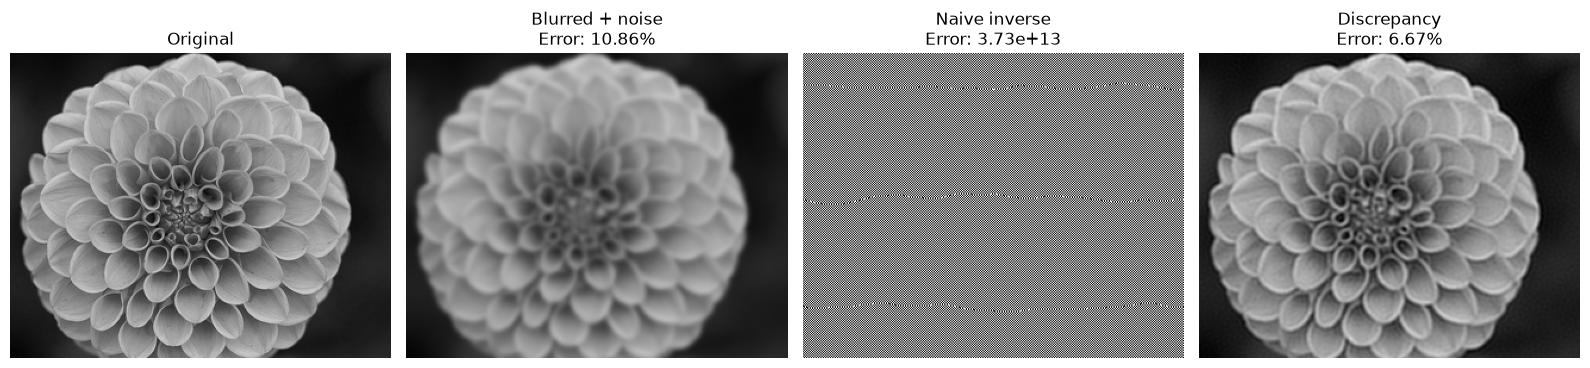

In [27]:
# YOUR CODE HERE
# Reuse the same noise draw from A3(c)
eta_f = 1e-3
B_f = B0 + eta_f * noise

# Reconstruct using both methods
naive = deblur_naive(B_f, kh)

lam_disc = discrepancy_lambda(B_f, kh, eta_f, lams)
regularized = deblur_tikhonov(B_f, kh, lam_disc)

# Select a central crop of the flower
crop = (slice(m // 5, 4 * m // 5),
        slice(n // 4, 3 * n // 4))

images = [img, B_f, naive, regularized]
titles = [
    "Original",
    f"Blurred + noise\nError: {rel(B_f):.2%}",
    f"Naive inverse\nError: {rel(naive):.2e}",
    f"Discrepancy\nError: {rel(regularized):.2%}"
]

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for ax, image, title in zip(axes, images, titles):
    ax.imshow(
        np.clip(image[crop], 0, 1),
        cmap="gray",
        vmin=0,
        vmax=1
    )
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

**Your answer.** The regularized reconstruction restores much of the flower's sharpness, especially the petal edges and details in the center. Some fine textures are still lost because the filter suppresses frequencies that are too strongly affected by the blur.

The naive inverse is completely corrupted because it amplifies noise in frequencies where the blur coefficients are very small.

---
# Extension — attempt **at most one** in the whole lab

End your extension with a paragraph headed **Finding**: one claim you can defend at the defence, supported by a number in this notebook.

## E1. Choosing λ when the noise level is unknown

*This topic was not lectured; the introduction below is all you need.*

The discrepancy principle needs $\eta$. **Generalised cross-validation** (GCV) does not. Write the Tikhonov reconstruction as $x_\lambda = C(\lambda)b$ and the fitted data as $Cx_\lambda = H_\lambda b$ with the *influence matrix* $H_\lambda = C(C^\top C + \lambda I)^{-1}C^\top$. GCV chooses the $\lambda$ that minimises
$$G(\lambda) = \frac{\frac1N\|(I - H_\lambda)b\|^2}{\left(\frac1N\operatorname{trace}(I - H_\lambda)\right)^2}, \qquad N = mn.$$
It approximates leave-one-out cross-validation: how well does the model predict a pixel it was not fitted to? The denominator penalises small $\lambda$, where $H_\lambda \approx I$ and the fit simply reproduces the noise.

**(a)** *Show* that the eigenvalues of $H_\lambda$ are the filter factors $f_j = |\hat c_j|^2/(|\hat c_j|^2+\lambda)$, so that $\operatorname{trace}(I - H_\lambda) = N - \sum_j f_j$, and that $\|(I-H_\lambda)b\| = \|(1-f)\hat b\|/\sqrt N$. Interpret $\sum_j f_j$ as an "effective number of parameters".

**Your answer.**

Reconstruct image from $b$ using Tikhonov:
$
b \xrightarrow{T_\lambda} x_\lambda^{\mathrm{Tik}}.
$

Apply the blur $C$ again:
$
x_\lambda^{\mathrm{Tik}}
\xrightarrow{C} Cx_\lambda^{\mathrm{Tik}}.
$

$H$ is a linear transformation which combines both:
$$
Cx_\lambda^{\mathrm{Tik}}=H_\lambda b:=CT_\lambda b,
\qquad H_\lambda:=CT_\lambda,
$$
where $T_\lambda$ is Tikhonov reconstruction operator:
$$
T_\lambda:=(C^\top C+\lambda I)^{-1}C^\top.
$$

In Fourier space blurring is multiplication by $\widehat c_j$:
$$
\widehat{Cx_\lambda^{\mathrm{Tik}}}_j
=\widehat c_j\widehat{x_\lambda^{\mathrm{Tik}}}_j
=\widehat c_j
\frac{\overline{\widehat c_j}\widehat b_j}
{|\widehat c_j|^2+\lambda}
=\frac{|\widehat c_j|^2}{|\widehat c_j|^2+\lambda}\widehat b_j
=f_{\lambda,j}\widehat b_j.
$$
$$
\widehat{H_\lambda b}_j=f_{\lambda,j}\widehat b_j.
$$

The formula above holds for any input, not only the observed image $b$.
Fix a frequency index $j$ and choose a vector $v$ such that
$\widehat v_j=1$ and all other Fourier coordinates are zero. Then
$$
\widehat{H_\lambda v}=f_{\lambda,j}\widehat v.
$$
Applying the inverse Fourier transform:
$$
\mathcal F^{-1}(\widehat{H_\lambda v})
=\mathcal F^{-1}(f_{\lambda,j}\widehat v),
$$
$$
H_\lambda v=f_{\lambda,j}v.
$$

This works for every frequency index $j$, and these chosen vectors form
the Fourier basis. Therefore the eigenvalues of $H_\lambda$ are precisely
the filter factors $f_{\lambda,j}$.

Generalized Cross-Validation function $G:\lambda\mapsto\text{score}$.

We search for
$
\operatorname*{arg\,min}_{\lambda>0}G(\lambda).
$
$$
G(\lambda)=
\frac{\frac1N\|(I-H_\lambda)b\|^2}
{\left(\frac1N\operatorname{tr}(I-H_\lambda)\right)^2}.
$$

Numerator: residual error (mean squared).

Denominator: square of the normalized remaining effective degrees of freedom.

Residual after reblurring:
$$
r_\lambda=(I-H_\lambda)b=b-Cx_\lambda^{\mathrm{Tik}}.
$$

The trace is the sum of eigenvalues. Since the eigenvalues of $H_\lambda$
are $f_{\lambda,j}$, the eigenvalues of $I-H_\lambda$ are $1-f_{\lambda,j}$.
Therefore, with $N=mn$ pixels,
$$
\operatorname{tr}(I-H_\lambda)
=\sum_j(1-f_{\lambda,j})
=N-\sum_j f_{\lambda,j}.
$$

For the residual after reblurring,
$$
r_\lambda=(I-H_\lambda)b=b-H_\lambda b.
$$
In Fourier space:
$$
\widehat r_{\lambda,j}
=\widehat b_j-\widehat{H_\lambda b}_j
=\widehat b_j-f_{\lambda,j}\widehat b_j
=(1-f_{\lambda,j})\widehat b_j.
$$

By Parseval's identity, for the unnormalized forward Fourier transform,
$$
\|r\|^2=\frac1N\sum_j|\widehat r_j|^2.
$$
Applying this to $r_\lambda$:
$$
\|(I-H_\lambda)b\|^2
=\frac1N\sum_j|(1-f_{\lambda,j})\widehat b_j|^2.
$$
Taking the square root:
$$
\|(I-H_\lambda)b\|
=\frac{\|(1-f_\lambda)\widehat b\|}{\sqrt N},
$$
where $f_\lambda$ is the vector of filter factors and the multiplication
is coordinatewise.

The sum $\sum_j f_{\lambda,j}$ is the effective number of parameters.
Each factor tells how much of a Fourier coordinate is retained in the
fitted data $H_\lambda b$. A factor close to $1$ contributes almost one
parameter; a factor close to $0$ contributes almost none. Factors between
$0$ and $1$ contribute fractions of a parameter.

Increasing $\lambda$ decreases the filter factors, so the effective
number of parameters decreases.

**(b)** Implement `gcv(B, kh, lam)` and choose $\lambda$ by minimising it over `lams`, for $\eta = 10^{-3}$ and $10^{-2}$. Compare the GCV choice with the oracle and with the discrepancy principle, and plot $G(\lambda)$ together with the error curve. Then estimate the noise level from the GCV fit, $\hat\eta^2 = \|(I - H_\lambda)b\|^2/\operatorname{trace}(I-H_\lambda)$, and compare it with the true $\eta$.

In [28]:
def gcv(B, kh, lam):
    # YOUR CODE HERE
    N = B.size

    Bhat = np.fft.fft2(B)

    # Tikhonov filter factors
    f = np.abs(kh)**2 / (np.abs(kh)**2 + lam)

    # Residual in Fourier space
    rhat = (1 - f) * Bhat

    # Residual squared norm (Parseval)
    residual_sq = np.sum(np.abs(rhat)**2) / N

    # Trace(I - H_lambda)
    dof = N - f.sum()

    # GCV numerator / denominator
    return (residual_sq / N) / (dof / N)**2


     eta |    oracle λ | oracle err |     disc. λ |  disc. err |       GCV λ |    GCV err |    eta_hat
   1e-03 |   5.623e-04 |     0.0667 |   5.623e-04 |     0.0667 |   1.778e-04 |     0.0689 |  9.934e-04
   1e-02 |   1.778e-02 |     0.0894 |   1.000e-02 |     0.0900 |   3.162e-03 |     0.1073 |  9.944e-03


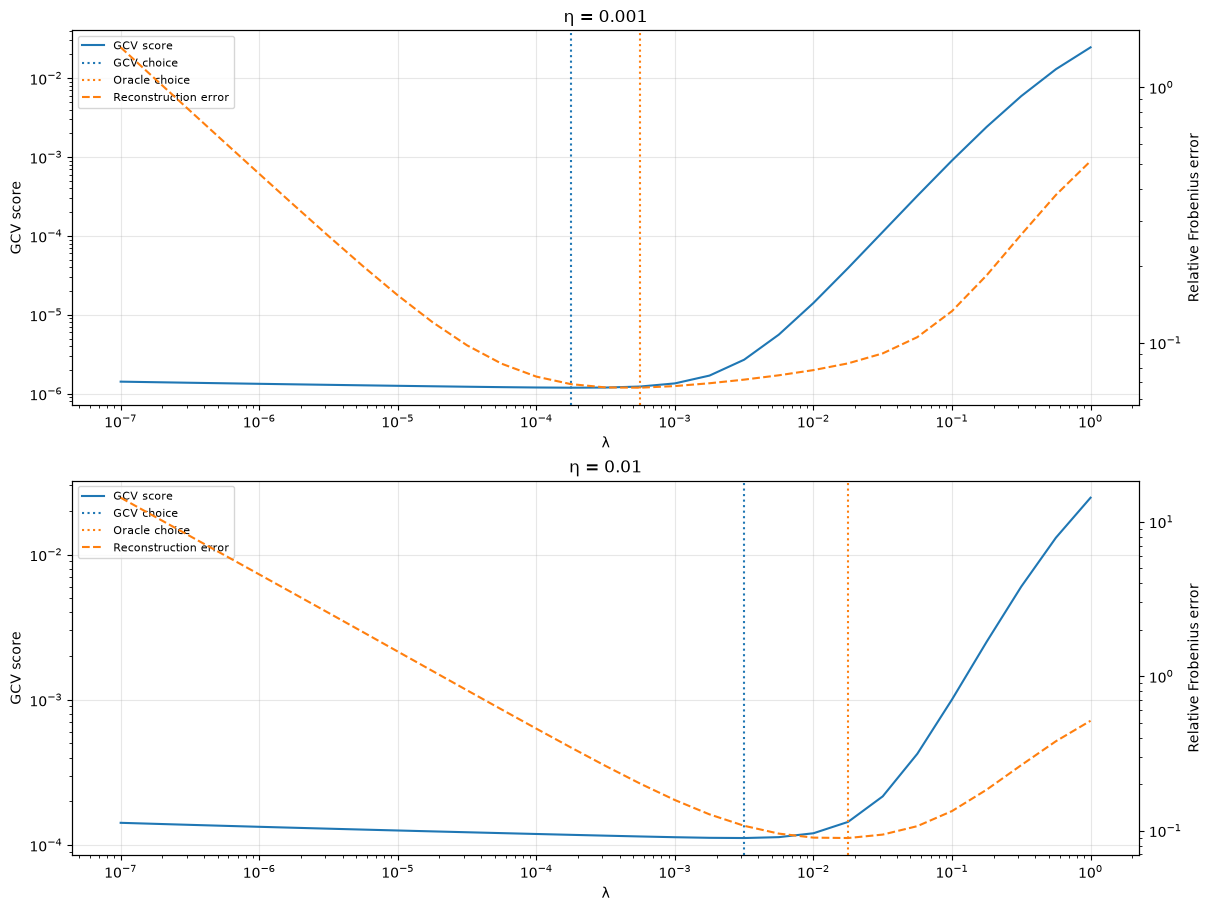

In [29]:
# YOUR CODE HERE
print(
    f"{'eta':>8} | {'oracle λ':>11} | {'oracle err':>10} | "
    f"{'disc. λ':>11} | {'disc. err':>10} | "
    f"{'GCV λ':>11} | {'GCV err':>10} | {'eta_hat':>10}"
)

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 9),
    constrained_layout=True
)

for ax, eta_ in zip(axes, [1e-3, 1e-2]):
    # Same noise draw, different noise magnitudes
    B_eta = B0 + eta_ * noise
    N = B_eta.size

    # GCV scores and actual reconstruction errors
    gcv_scores = np.array([
        gcv(B_eta, kh, lam) for lam in lams
    ])

    errors = np.array([
        rel(deblur_tikhonov(B_eta, kh, lam))
        for lam in lams
    ])

    # GCV and oracle choices
    i_gcv = np.argmin(gcv_scores)
    i_oracle = np.argmin(errors)

    lam_gcv = lams[i_gcv]
    lam_oracle = lams[i_oracle]

    # Discrepancy principle
    lam_disc = discrepancy_lambda(B_eta, kh, eta_, lams)
    i_disc = np.flatnonzero(np.isclose(lams, lam_disc))[0]

    # Estimate eta using the GCV-selected lambda
    Bhat = np.fft.fft2(B_eta)
    f = np.abs(kh)**2 / (np.abs(kh)**2 + lam_gcv)

    rhat = (1 - f) * Bhat
    residual_sq = np.sum(np.abs(rhat)**2) / N

    dof = N - f.sum()
    eta_hat = np.sqrt(residual_sq / dof)

    print(
        f"{eta_:8.0e} | {lam_oracle:11.3e} | {errors[i_oracle]:10.4f} | "
        f"{lam_disc:11.3e} | {errors[i_disc]:10.4f} | "
        f"{lam_gcv:11.3e} | {errors[i_gcv]:10.4f} | {eta_hat:10.3e}"
    )

    # Plot GCV and reconstruction error on separate y-axes
    ax.plot(lams, gcv_scores, label="GCV score")
    ax.set_xscale("log")
    ax.set_xlabel("λ")
    ax.set_ylabel("GCV score")

    ax2 = ax.twinx()
    ax2.plot(
        lams, errors, "--",
        color="tab:orange", label="Reconstruction error"
    )
    ax2.set_ylabel("Relative Frobenius error")

    ax.axvline(
        lam_gcv, color="tab:blue",
        linestyle=":", label="GCV choice"
    )
    ax.axvline(
        lam_oracle, color="tab:orange",
        linestyle=":", label="Oracle choice"
    )

    ax.set_title(f"η = {eta_:g}")
    ax.grid(True, alpha=0.3)

    lines = ax.get_lines() + ax2.get_lines()
    ax.legend(
        lines,
        [line.get_label() for line in lines],
        fontsize=8
    )

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax2.set_xscale("log")
    ax2.set_yscale("log")

plt.show()

**Your answer.** For $\eta=0.001$, GCV gives $6.89\%$ error, compared with $6.67\%$ for both the oracle and discrepancy principle. For $\eta=0.01$, GCV gives $10.73\%$, compared with $8.94\%$ for the oracle and $9.00\%$ for discrepancy.

GCV estimates the noise levels accurately ($0.0009934$ and $0.0099441$), but this does not guarantee the best reconstruction. GCV evaluates prediction error in the blurred data, while the oracle measures error against the original image. GCV also selects smaller $\lambda$ values, allowing more noise amplification.

**Finding.** GCV works without knowing the original image or noise level, but its reconstruction can be less accurate than the oracle's, especially at higher noise levels.


---
**Before you submit:** run `Kernel → Restart & Run All`, check that every written answer is filled in, and make sure your extension (if any) ends with a **Finding**.